# Backpropagation in Multilayer Neural Networks

- [sklearn.datasets.load_digits](http://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits)

In [84]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits

digits = load_digits()

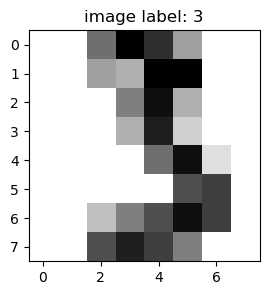

In [85]:
sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(digits.images[sample_index], cmap=plt.cm.gray_r,
           interpolation='nearest')
plt.title("image label: %d" % digits.target[sample_index]);

In [86]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

data = np.asarray(digits.data, dtype='float32')
target = np.asarray(digits.target, dtype='int32')

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.15, random_state=37)

# mean = 0 ; standard deviation = 1.0
scaler = preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(scaler.mean_)
print(scaler.scale_)

[0.00000000e+00 2.98624754e-01 5.19253438e+00 1.18428291e+01
 1.18565815e+01 5.81008513e+00 1.34774067e+00 1.19187950e-01
 6.54878847e-03 1.99345121e+00 1.03464309e+01 1.19305828e+01
 1.02626064e+01 8.20497708e+00 1.84348396e+00 9.88867060e-02
 3.27439424e-03 2.61624100e+00 9.83497053e+00 6.87098887e+00
 7.11263916e+00 7.83759005e+00 1.75376555e+00 4.45317616e-02
 1.30975769e-03 2.48788474e+00 9.04453176e+00 8.73280943e+00
 9.98231827e+00 7.57105435e+00 2.26850033e+00 2.61951539e-03
 0.00000000e+00 2.36149312e+00 7.68369352e+00 9.07924034e+00
 1.03713163e+01 8.79240341e+00 2.89980354e+00 0.00000000e+00
 8.51342502e-03 1.57039948e+00 6.84937787e+00 7.22855272e+00
 7.65029470e+00 8.26522593e+00 3.48592010e+00 2.61951539e-02
 8.51342502e-03 6.83693517e-01 7.49312377e+00 9.56516045e+00
 9.36869679e+00 8.77668631e+00 3.76686313e+00 2.08906352e-01
 6.54878847e-04 2.78978389e-01 5.53700065e+00 1.20595940e+01
 1.17832351e+01 6.81990832e+00 2.07465619e+00 3.42501637e-01]
[1.         0.91047427 

In [87]:
X_train.shape

(1527, 64)

In [88]:
X_train.dtype

dtype('float32')

In [89]:
X_test.shape

(270, 64)

In [90]:
y_train.shape

(1527,)

In [91]:
y_train.dtype

dtype('int32')

In [92]:
def one_hot(n_classes, y):
    return np.eye(n_classes)[y]

In [93]:
one_hot(n_classes=10, y=3)

array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])

In [94]:
one_hot(n_classes=10, y=[0, 4, 9, 1])

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [95]:
def softmax(X):
    exp_X = np.exp(X)
    return exp_X / np.sum(exp_X, axis=-1, keepdims=True)

In [96]:
print(softmax([10, 2, -3]))

[9.99662391e-01 3.35349373e-04 2.25956630e-06]


In [97]:
X = np.array([[10, 2, -3],
              [-1, 5, -20]])
print(softmax(X))

[[9.99662391e-01 3.35349373e-04 2.25956630e-06]
 [2.47262316e-03 9.97527377e-01 1.38536042e-11]]


In [99]:
print(np.sum(softmax([10, 2, -3])))

1.0


In [100]:
print("sotfmax of 2 vectors:")
X = np.array([[10, 2, -3],
              [-1, 5, -20]])
print(softmax(X))

sotfmax of 2 vectors:
[[9.99662391e-01 3.35349373e-04 2.25956630e-06]
 [2.47262316e-03 9.97527377e-01 1.38536042e-11]]


In [101]:
print(np.sum(softmax(X), axis=1))

[1. 1.]


In [102]:
def nll(Y_true, Y_pred):
    Y_true = np.asarray(Y_true)
    Y_pred = np.asarray(Y_pred)
    
    # TODO
    epsilon = 1e-15
    Y_pred = np.clip(Y_pred, epsilon, 1 - epsilon)
    loss = -np.sum(Y_true * np.log(Y_pred), axis=-1)
    return np.mean(loss)    

# Make sure that it works for a simple sample at a time
print(nll([1, 0, 0], [.99, 0.01, 0]))

0.01005033585350145


In [103]:
print(nll([1, 0, 0], [0.01, 0.01, .98]))

4.605170185988091


In [104]:
def nll(Y_true, Y_pred):
    Y_true = np.atleast_2d(Y_true)
    Y_pred = np.atleast_2d(Y_pred)
    
    # TODO
    epsilon = 1e-15
    Y_pred = np.clip(Y_pred, epsilon, 1 - epsilon)
    loss = -np.sum(Y_true * np.log(Y_pred), axis=1)
    return np.mean(loss)   

In [ ]:

Y_true = np.array([[0, 1, 0],
                   [1, 0, 0],
                   [0, 0, 1]])

Y_pred = np.array([[0,   1,    0],
                   [.99, 0.01, 0],
                   [0,   0,    1]])

print(nll(Y_true, Y_pred))

0.003350111951167816


In [107]:
class LogisticRegression():

    def __init__(self, input_size, output_size):
        self.W = np.random.uniform(size=(input_size, output_size),
                                   high=0.1, low=-0.1)
        self.b = np.random.uniform(size=output_size,
                                   high=0.1, low=-0.1)
        self.output_size = output_size
        
    def forward(self, X):
        Z = np.dot(X, self.W) + self.b
        return softmax(Z)
    
    def predict(self, X):
        if len(X.shape) == 1:
            return np.argmax(self.forward(X))
        else:
            return np.argmax(self.forward(X), axis=1)
    
    def grad_loss(self, x, y_true):
        y_pred = self.forward(x)
        dnll_output =  y_pred - one_hot(self.output_size, y_true)
        grad_W = np.outer(x, dnll_output)
        grad_b = dnll_output
        grads = {"W": grad_W, "b": grad_b}
        return grads
    
    def train(self, x, y, learning_rate):
        # Traditional SGD update without momentum
        grads = self.grad_loss(x, y)
        self.W = self.W - learning_rate * grads["W"]
        self.b = self.b - learning_rate * grads["b"]      
        
    def loss(self, X, y):
        return nll(one_hot(self.output_size, y), self.forward(X))

    def accuracy(self, X, y):
        y_preds = np.argmax(self.forward(X), axis=1)
        return np.mean(y_preds == y)

In [ ]:
n_features = X_train.shape[1]
n_classes = len(np.unique(y_train))
lr = LogisticRegression(n_features, n_classes)

print("Evaluation of the untrained model:")
train_loss = lr.loss(X_train, y_train)
train_acc = lr.accuracy(X_train, y_train)
test_acc = lr.accuracy(X_test, y_test)

print("train loss: %0.4f, train acc: %0.3f, test acc: %0.3f"
      % (train_loss, train_acc, test_acc))

Evaluation of the untrained model:
train loss: 2.4276, train acc: 0.090, test acc: 0.070


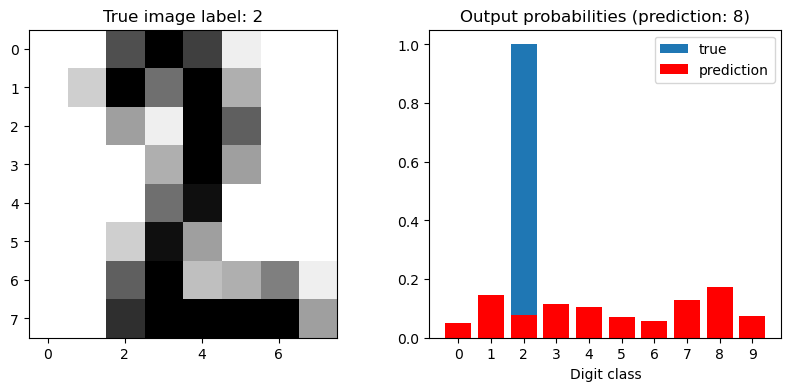

In [109]:
def plot_prediction(model, sample_idx=0, classes=range(10)):
    fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

    ax0.imshow( scaler.inverse_transform(X_test[sample_idx].reshape(1, -1)).reshape(8, 8), cmap=plt.cm.gray_r,
               interpolation='nearest')
    ax0.set_title("True image label: %d" % y_test[sample_idx]);


    ax1.bar(classes, one_hot(len(classes), y_test[sample_idx]), label='true')
    ax1.bar(classes, model.forward(X_test[sample_idx]), label='prediction', color="red")
    ax1.set_xticks(classes)
    prediction = model.predict(X_test[sample_idx])
    ax1.set_title('Output probabilities (prediction: %d)'
                  % prediction)
    ax1.set_xlabel('Digit class')
    ax1.legend()
    
plot_prediction(lr, sample_idx=0)

In [ ]:
learning_rate = 0.01

for i, (x, y) in enumerate(zip(X_train, y_train)):
    lr.train(x, y, learning_rate)
    if i % 100 == 0:
        train_loss = lr.loss(X_train, y_train)
        train_acc = lr.accuracy(X_train, y_train)
        test_acc = lr.accuracy(X_test, y_test)
        print("Update #%d, train loss: %0.4f, train acc: %0.3f, test acc: %0.3f"
              % (i, train_loss, train_acc, test_acc))

Update #0, train loss: 2.3904, train acc: 0.091, test acc: 0.063
Update #100, train loss: 1.2893, train acc: 0.743, test acc: 0.741
Update #200, train loss: 0.8507, train acc: 0.868, test acc: 0.874
Update #300, train loss: 0.6330, train acc: 0.910, test acc: 0.900
Update #400, train loss: 0.5212, train acc: 0.916, test acc: 0.919
Update #500, train loss: 0.4502, train acc: 0.925, test acc: 0.922
Update #600, train loss: 0.3964, train acc: 0.932, test acc: 0.926
Update #700, train loss: 0.3598, train acc: 0.937, test acc: 0.948
Update #800, train loss: 0.3355, train acc: 0.942, test acc: 0.948
Update #900, train loss: 0.3115, train acc: 0.948, test acc: 0.948
Update #1000, train loss: 0.2942, train acc: 0.948, test acc: 0.952
Update #1100, train loss: 0.2758, train acc: 0.946, test acc: 0.959
Update #1200, train loss: 0.2635, train acc: 0.949, test acc: 0.963
Update #1300, train loss: 0.2582, train acc: 0.948, test acc: 0.948
Update #1400, train loss: 0.2438, train acc: 0.950, test acc

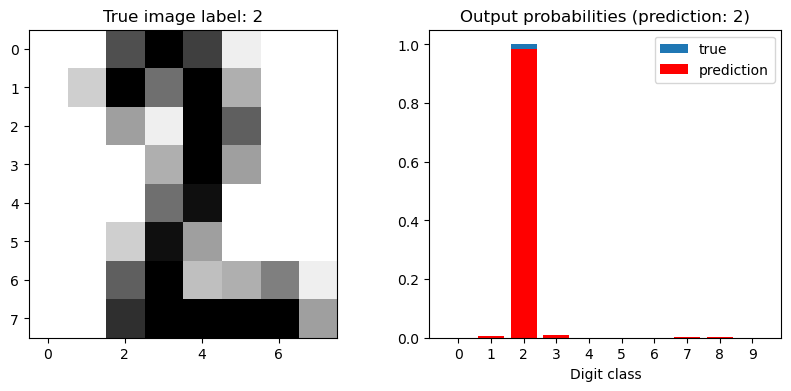

In [111]:
plot_prediction(lr, sample_idx=0)

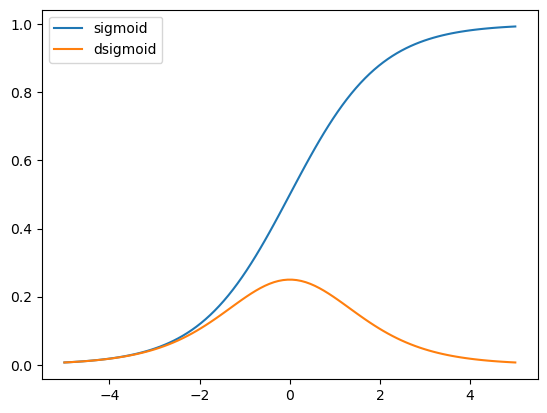

In [112]:
def sigmoid(X):
    # TODO
    return 1 / (1 + np.exp(-X))


def dsigmoid(X):
    # TODO
    s = sigmoid(X)
    return s * (1 - s)


x = np.linspace(-5, 5, 100)
plt.plot(x, sigmoid(x), label='sigmoid')
plt.plot(x, dsigmoid(x), label='dsigmoid')
plt.legend(loc='best');

In [ ]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def dsigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

def softmax(X):
    shift_X = X - np.max(X, axis=-1, keepdims=True)
    exp_X = np.exp(shift_X)
    return exp_X / np.sum(exp_X, axis=-1, keepdims=True)

EPSILON = 1e-8

class NeuralNet():
    """MLP with 1 hidden layer with a sigmoid activation"""
    
    def __init__(self, input_size, hidden_size, output_size):
        # Xavier Initialization: helps gradients flow better than random small values
        self.W_h = np.random.randn(input_size, hidden_size) * np.sqrt(1. / input_size)
        self.b_h = np.zeros((1, hidden_size))
        self.W_o = np.random.randn(hidden_size, output_size) * np.sqrt(1. / hidden_size)
        self.b_o = np.zeros((1, output_size))
        self.output_size = output_size
            
    def forward_keep_activations(self, X):
        if X.ndim == 1: X = X.reshape(1, -1)
        
        z_h = np.dot(X, self.W_h) + self.b_h
        h = sigmoid(z_h)
        
        z_o = np.dot(h, self.W_o) + self.b_o
        y = softmax(z_o)
        
        return y, h, z_h

    def forward(self, X):
        y, h, z_h = self.forward_keep_activations(X)
        return y
    
    def loss(self, X, y_true):
        y_pred = self.forward(X)
        # Negative Log Likelihood
        y_pred = np.clip(y_pred, EPSILON, 1. - EPSILON)
        log_likelihood = -np.sum(y_true * np.log(y_pred), axis=1)
        return np.mean(log_likelihood)

    def grad_loss(self, x, y_true):
        if x.ndim == 1: x = x.reshape(1, -1)
        if y_true.ndim == 1: y_true = y_true.reshape(1, -1)
        n_samples = x.shape[0]
        
        y_pred, h, z_h = self.forward_keep_activations(x)
        
        delta_o = (y_pred - y_true)  
        
        dW_o = np.dot(h.T, delta_o) / n_samples
        db_o = np.mean(delta_o, axis=0, keepdims=True)
        
        delta_h = np.dot(delta_o, self.W_o.T) * dsigmoid(z_h)
        
        dW_h = np.dot(x.T, delta_h) / n_samples
        db_h = np.mean(delta_h, axis=0, keepdims=True)

        return {"W_h": dW_h, "b_h": db_h, "W_o": dW_o, "b_o": db_o}

    def train(self, x, y, learning_rate):
        grads = self.grad_loss(x, y)
        
        self.W_h -= learning_rate * grads["W_h"]
        self.b_h -= learning_rate * grads["b_h"]
        self.W_o -= learning_rate * grads["W_o"]
        self.b_o -= learning_rate * grads["b_o"]

    def predict(self, X):
        y_pred = self.forward(X)
        if y_pred.shape[0] == 1:
            return np.argmax(y_pred)
        else:
            return np.argmax(y_pred, axis=1)

    def accuracy(self, X, y):
        y_preds = self.predict(X)
        return np.mean(y_preds == y)

In [116]:
n_hidden = 10
model = NeuralNet(n_features, n_hidden, n_classes)

In [117]:
y_train_onehot = one_hot(n_classes, y_train)
y_test_onehot = one_hot(n_classes, y_test)

model.loss(X_train, y_train_onehot)

np.float64(2.4380144285129695)

In [118]:
model.accuracy(X_train, y_train)

np.float64(0.07007203667321546)

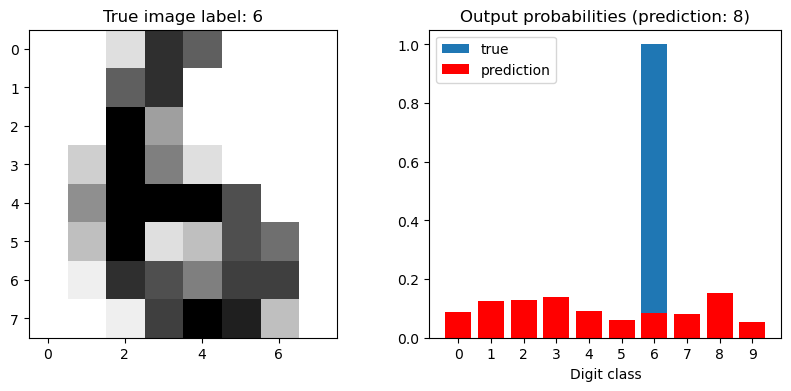

In [ ]:
class PlotModelWrapper:
    def __init__(self, model):
        self.model = model

    def forward(self, X):
        return self.model.forward(X).flatten()

    def predict(self, X):
        return self.model.predict(X)
plot_prediction(PlotModelWrapper(model), sample_idx=133)

In [120]:
losses, accuracies, accuracies_test = [], [], []
losses.append(model.loss(X_train, y_train_onehot))
accuracies.append(model.accuracy(X_train, y_train))
accuracies_test.append(model.accuracy(X_test, y_test))

print("Random init: train loss: %0.5f, train acc: %0.3f, test acc: %0.3f"
      % (losses[-1], accuracies[-1], accuracies_test[-1]))

for epoch in range(15):
    for i, (x, y) in enumerate(zip(X_train, y_train)):
        model.train(x, y, 0.1)

    losses.append(model.loss(X_train, y_train_onehot))
    accuracies.append(model.accuracy(X_train, y_train))
    accuracies_test.append(model.accuracy(X_test, y_test))
    print("Epoch #%d, train loss: %0.5f, train acc: %0.3f, test acc: %0.3f"
          % (epoch + 1, losses[-1], accuracies[-1], accuracies_test[-1]))

Random init: train loss: 2.43801, train acc: 0.070, test acc: 0.119
Epoch #1, train loss: 2.30366, train acc: 0.081, test acc: 0.096
Epoch #2, train loss: 2.30359, train acc: 0.075, test acc: 0.078
Epoch #3, train loss: 2.30212, train acc: 0.128, test acc: 0.163
Epoch #4, train loss: 2.30238, train acc: 0.136, test acc: 0.170
Epoch #5, train loss: 2.30259, train acc: 0.113, test acc: 0.148
Epoch #6, train loss: 2.30259, train acc: 0.094, test acc: 0.119
Epoch #7, train loss: 2.30259, train acc: 0.094, test acc: 0.119
Epoch #8, train loss: 2.30259, train acc: 0.103, test acc: 0.107
Epoch #9, train loss: 2.30259, train acc: 0.092, test acc: 0.104
Epoch #10, train loss: 2.30259, train acc: 0.096, test acc: 0.104
Epoch #11, train loss: 2.30259, train acc: 0.102, test acc: 0.107
Epoch #12, train loss: 2.30259, train acc: 0.103, test acc: 0.111
Epoch #13, train loss: 2.30259, train acc: 0.102, test acc: 0.111
Epoch #14, train loss: 2.30259, train acc: 0.102, test acc: 0.111
Epoch #15, train 

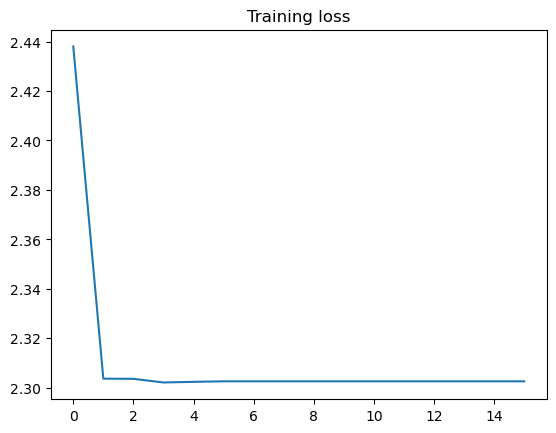

In [121]:
plt.plot(losses)
plt.title("Training loss");

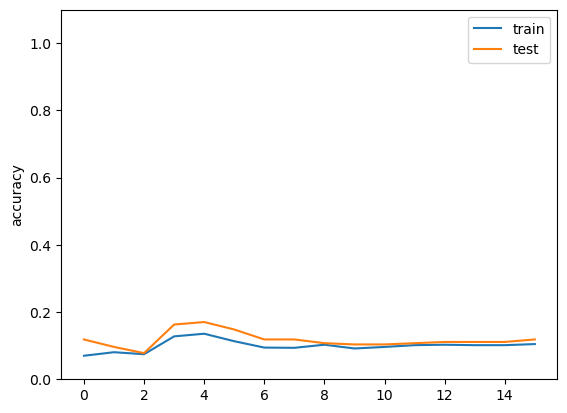

In [122]:
plt.plot(accuracies, label='train')
plt.plot(accuracies_test, label='test')
plt.ylim(0, 1.1)
plt.ylabel("accuracy")
plt.legend(loc='best');

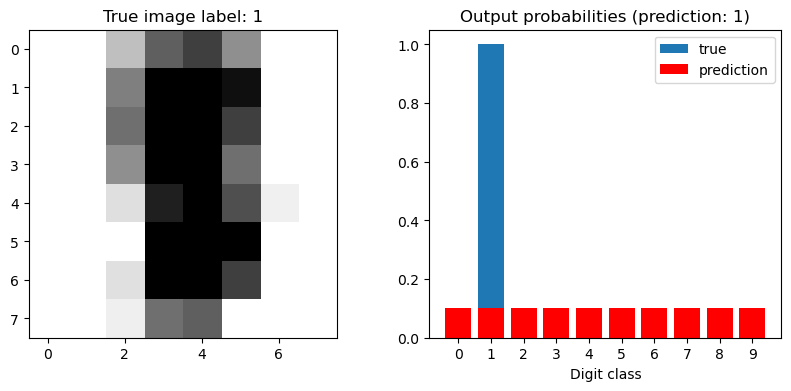

In [124]:
plot_prediction(PlotModelWrapper(model), sample_idx=4)

Worst sample indices: [ 99  13 130 186  21]
Confidence in correct class for these: [0.09999954 0.09999961 0.09999964 0.09999969 0.09999976]

--- Worst Prediction Analysis (Index 99) ---

--- Worst Prediction Analysis (Index 13) ---

--- Worst Prediction Analysis (Index 130) ---

--- Worst Prediction Analysis (Index 186) ---

--- Worst Prediction Analysis (Index 21) ---


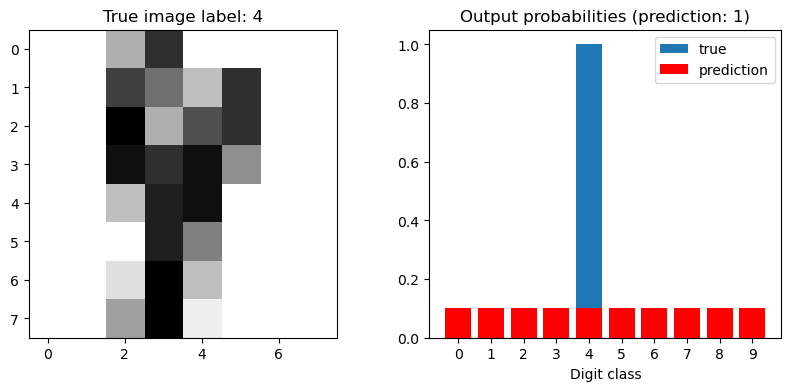

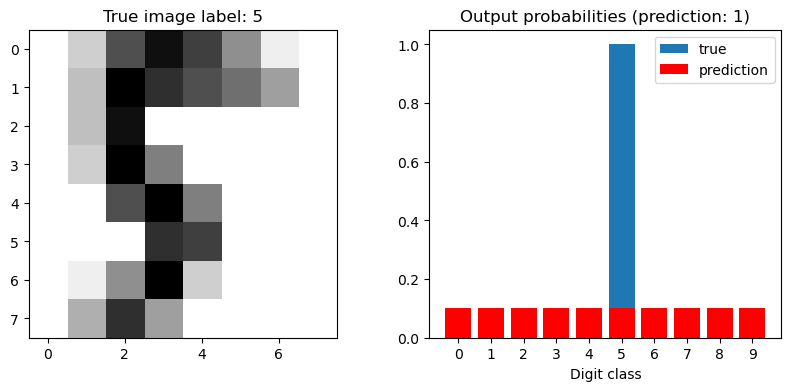

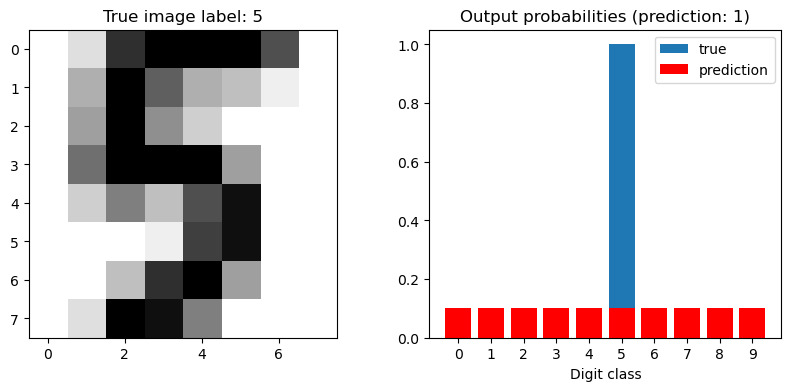

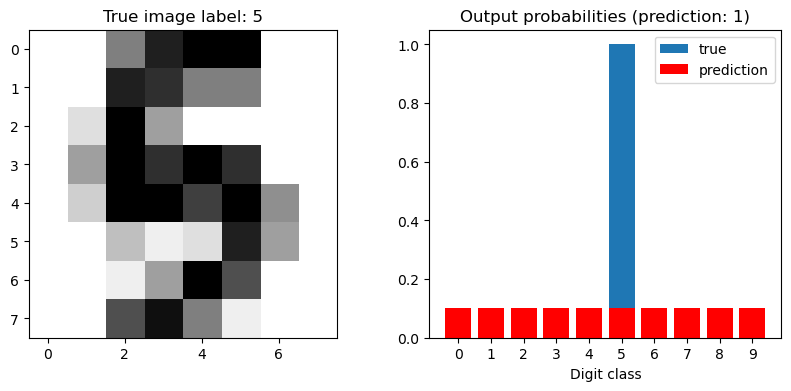

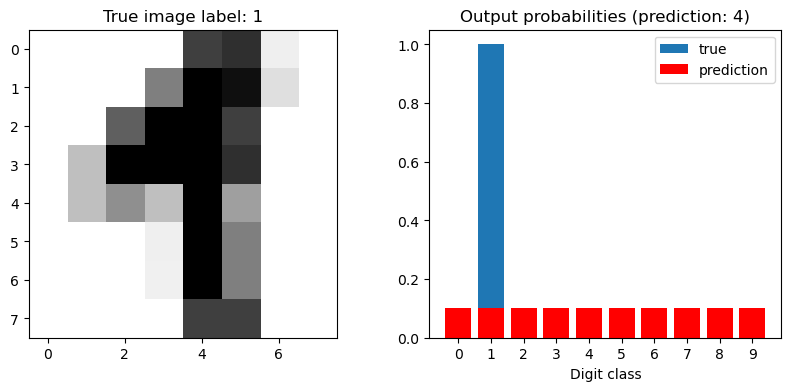

In [ ]:
y_pred_probs = model.forward(X_test)
true_class_probs = y_pred_probs[np.arange(len(y_test)), y_test]
worst_indices = np.argsort(true_class_probs)[:5] 
print(f"Worst sample indices: {worst_indices}")
print(f"Confidence in correct class for these: {true_class_probs[worst_indices]}")
for idx in worst_indices:
    print(f"\n--- Worst Prediction Analysis (Index {idx}) ---")
    plot_prediction(PlotModelWrapper(model), idx)

In [ ]:
# Write your code here.

def relu(x):
    return np.maximum(0, x)

def drelu(x):
    return (x > 0).astype(float)

def tanh(x):
    return np.tanh(x)

def dtanh(x):
    return 1.0 - np.tanh(x)**2

class NeuralNet():
    def __init__(self, input_size, hidden_size, output_size, activation='sigmoid'):
        self.activation_type = activation
        
        init_std = np.sqrt(2. / input_size) if activation == 'relu' else np.sqrt(1. / input_size)
        
        self.W_h = np.random.randn(input_size, hidden_size) * init_std
        self.b_h = np.zeros((1, hidden_size))
        self.W_o = np.random.randn(hidden_size, output_size) * np.sqrt(1. / hidden_size)
        self.b_o = np.zeros((1, output_size))

    def _activate(self, x):
        if self.activation_type == 'relu': return relu(x)
        if self.activation_type == 'tanh': return tanh(x)
        return sigmoid(x)

    def _d_activate(self, x):
        if self.activation_type == 'relu': return drelu(x)
        if self.activation_type == 'tanh': return dtanh(x)
        return dsigmoid(x)

    def forward_keep_activations(self, X):
        if X.ndim == 1: X = X.reshape(1, -1)
        z_h = np.dot(X, self.W_h) + self.b_h
        h = self._activate(z_h)
        z_o = np.dot(h, self.W_o) + self.b_o
        y = softmax(z_o)
        return y, h, z_h

    def grad_loss(self, x, y_true):
        y_pred, h, z_h = self.forward_keep_activations(x)
        n = x.shape[0]
        
        delta_o = (y_pred - y_true)
        dW_o = np.dot(h.T, delta_o) / n
        db_o = np.mean(delta_o, axis=0, keepdims=True)
        
        delta_h = np.dot(delta_o, self.W_o.T) * self._d_activate(z_h)
        
        dW_h = np.dot(x.T, delta_h) / n
        db_h = np.mean(delta_h, axis=0, keepdims=True)
        
        return {"W_h": dW_h, "b_h": db_h, "W_o": dW_o, "b_o": db_o}
    
    def loss(self, X, y_true):
        y_pred = self.forward(X)
        y_pred = np.clip(y_pred, EPSILON, 1. - EPSILON)
        log_likelihood = -np.sum(y_true * np.log(y_pred), axis=1)
        return np.mean(log_likelihood)

    def grad_loss(self, x, y_true):
        if x.ndim == 1: x = x.reshape(1, -1)
        if y_true.ndim == 1: y_true = y_true.reshape(1, -1)
        n_samples = x.shape[0]
        
        y_pred, h, z_h = self.forward_keep_activations(x)
        
        delta_o = (y_pred - y_true)  
        
        dW_o = np.dot(h.T, delta_o) / n_samples
        db_o = np.mean(delta_o, axis=0, keepdims=True)
        
        delta_h = np.dot(delta_o, self.W_o.T) * dsigmoid(z_h)
        
        dW_h = np.dot(x.T, delta_h) / n_samples
        db_h = np.mean(delta_h, axis=0, keepdims=True)

        return {"W_h": dW_h, "b_h": db_h, "W_o": dW_o, "b_o": db_o}

    def train(self, x, y, learning_rate):
        grads = self.grad_loss(x, y)
        
        self.W_h -= learning_rate * grads["W_h"]
        self.b_h -= learning_rate * grads["b_h"]
        self.W_o -= learning_rate * grads["W_o"]
        self.b_o -= learning_rate * grads["b_o"]

    def predict(self, X):
        y_pred = self.forward(X)
        if y_pred.shape[0] == 1:
            return np.argmax(y_pred)
        else:
            return np.argmax(y_pred, axis=1)

    def accuracy(self, X, y):
        y_preds = self.predict(X)
        return np.mean(y_preds == y)
    def forward(self, X):
        y, h, z_h = self.forward_keep_activations(X)
        return y

results = {}

for size in [64, 256]:
    for lr in [0.1, 0.5]:
        model = NeuralNet(X_train.shape[1], size, 10, activation='relu')
        acc = model.accuracy(X_test, y_test)
        results[f"Size:{size}, LR:{lr}"] = acc

print(results)

{'Size:64, LR:0.1': np.float64(0.05185185185185185), 'Size:64, LR:0.5': np.float64(0.07777777777777778), 'Size:256, LR:0.1': np.float64(0.09259259259259259), 'Size:256, LR:0.5': np.float64(0.08518518518518518)}


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_onehot, epochs=50, verbose=0, 
                    validation_data=(X_test, y_test_onehot))

import tensorflow.keras.losses as losses

y_pred_42 = model.predict(X_test[42:43], verbose=0)
nll_42 = losses.categorical_crossentropy(y_test_onehot[42:43], y_pred_42).numpy()[0]

nll_test = model.evaluate(X_test, y_test_onehot, verbose=0)[0]
nll_train = model.evaluate(X_train, y_train_onehot, verbose=0)[0]

print(f"NLL Sample 42: {nll_42:.4f}")
print(f"Avg Test NLL:  {nll_test:.4f}")
print(f"Avg Train NLL: {nll_train:.4f} (Matches Keras Loss: {history.history['loss'][-1]:.4f})")

train_acc, test_acc = history.history['accuracy'][-1], history.history['val_accuracy'][-1]

if train_acc > test_acc + 0.05:
    status = "Overfitting (High variance)"
elif train_acc < 0.85:
    status = "Underfitting (High bias)"
else:
    status = "Well-fitted"

print(f"Status: {status} | Train Acc: {train_acc:.2%} | Test Acc: {test_acc:.2%}")

NLL Sample 42: 0.4659
Avg Test NLL:  0.4463
Avg Train NLL: 0.4669 (Matches Keras Loss: 0.4721)
Status: Well-fitted | Train Acc: 92.80% | Test Acc: 93.70%


In [ ]:
# The model is well fitted like the training lass suggest. It reaches a sufficent convergence.